[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.3/Problem_3.8.ipynb)

# Chapter 3, Problem 8 — drawing $\tilde dt$ and $\tilde dx$

**Problem.** Draw the basis one-forms $\tilde dt$ and $\tilde dx$ of a frame $\mathcal O$.

## What to draw

A one-form is pictured as a family of parallel surfaces (lines, in the $t$–$x$ plane). Its value on a vector is the number of surfaces the vector's arrow crosses (§3.3, Figs. 3.1, 3.4).

- $\tilde dt$ is the gradient of the function $t$ (Eq. 3.20: $\tilde dx^\alpha = \tilde\omega^\alpha$). Its surfaces are the level sets $t = 0, \pm1, \pm2, \dots$: **horizontal lines one unit apart**, with the sense of "increasing $t$" upward.
- $\tilde dx$ is the gradient of $x$: the **vertical lines** $x = 0, \pm1, \pm2, \dots$, increasing to the right.

**Check with the basis vectors** (Eq. 3.12, $\tilde\omega^\alpha(\vec e_\beta) = \delta^\alpha{}_\beta$):
- $\vec e_0$ (one unit up) crosses exactly **one** $t$-line, so $\tilde dt(\vec e_0) = 1$; it runs *along* the $x$-lines, crossing none: $\tilde dx(\vec e_0) = 0$.
- $\vec e_1$ (one unit right) crosses one $x$-line, $\tilde dx(\vec e_1) = 1$, and no $t$-lines, $\tilde dt(\vec e_1) = 0$.
- A general vector $\vec V \to (V^0, V^1)$ crosses $V^0$ $t$-lines and $V^1$ $x$-lines: $\tilde dt(\vec V) = V^0$, $\tilde dx(\vec V) = V^1$.

Note the picture of $\tilde dt$ doesn't depend on any metric: it's just "how fast $t$ changes". The *vector* associated with $\tilde dt$ via the metric is $-\vec e_0$ (Eq. 3.45), pointing **down**, opposite to the direction of increasing $t$. That's one of the places where the one-form picture is more natural.

The right panel adds the moving frame's $\tilde d\bar t$ ($v = 0.5$) for comparison. Its surfaces are $\bar{\mathcal O}$'s lines of simultaneity, tilted with slope $v$, and spaced $1/\gamma$ apart along the $t$ axis.

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

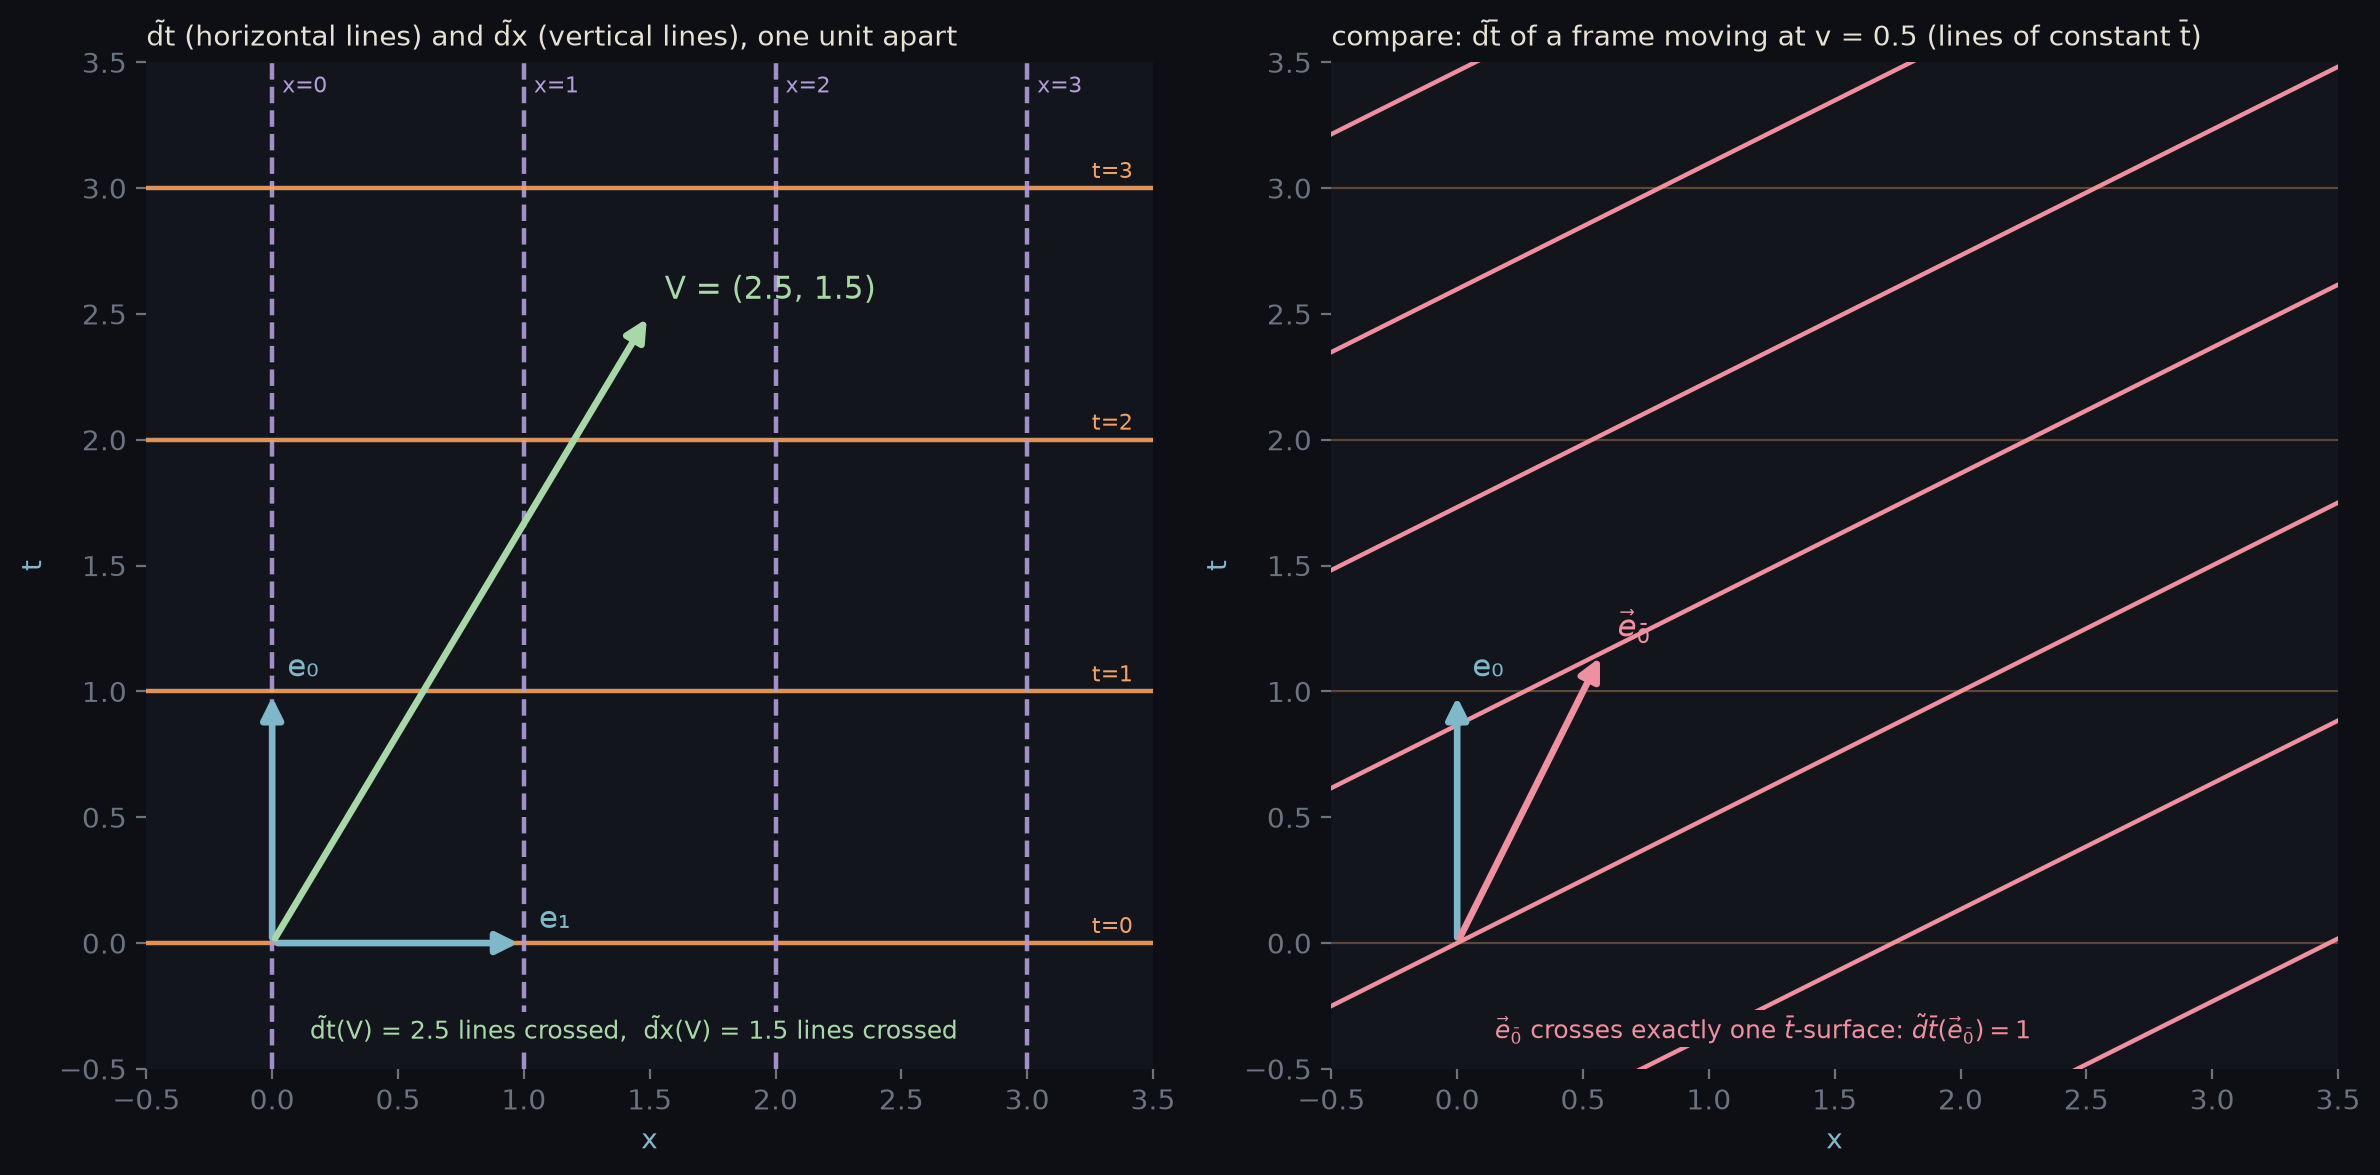

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from schutz_gr.diagrams import COLORS
%config InlineBackend.figure_format = 'retina'

fig, axs = plt.subplots(1, 2, figsize=(12, 6)); fig.patch.set_facecolor(COLORS["bg"])
lim = (-0.5, 3.5)
def frame(ax, title):
    ax.set_facecolor(COLORS["panel"]); ax.set_xlim(*lim); ax.set_ylim(*lim); ax.set_aspect("equal")
    ax.tick_params(colors=COLORS["grey"]); ax.set_title(title, color=COLORS["text"], loc="left", fontsize=10)
    ax.set_xlabel("x", color=COLORS["teal"]); ax.set_ylabel("t", color=COLORS["teal"])
    for s in ax.spines.values(): s.set_visible(False)
def arrow(ax, v, c, lab):
    ax.annotate("", xy=(v[1], v[0]), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2.4, mutation_scale=16))
    ax.text(v[1] + 0.06, v[0] + 0.06, lab, color=c, fontsize=11)

ax = axs[0]; frame(ax, "d̃t (horizontal lines) and d̃x (vertical lines), one unit apart")
for n in range(0, 4):
    ax.axhline(n, color=COLORS["amber"], lw=1.6, alpha=0.9); ax.text(3.42, n + 0.04, f"t={n}", color=COLORS["amber"], fontsize=8, ha="right")
    ax.axvline(n, color=COLORS["violet"], lw=1.6, alpha=0.9, ls="--"); ax.text(n + 0.04, 3.38, f"x={n}", color=COLORS["violet"], fontsize=8)
arrow(ax, (1, 0), COLORS["teal"], "e₀"); arrow(ax, (0, 1), COLORS["teal"], "e₁")
V = (2.5, 1.5); arrow(ax, V, COLORS["green"], "V = (2.5, 1.5)")
ax.text(0.15, -0.38, "d̃t(V) = 2.5 lines crossed,  d̃x(V) = 1.5 lines crossed", color=COLORS["green"], fontsize=9, bbox=dict(facecolor=COLORS["panel"], edgecolor="none", pad=1))

ax = axs[1]; frame(ax, "compare: d̃t̄ of a frame moving at v = 0.5 (lines of constant t̄)")
v = 0.5; g = 1/np.sqrt(1 - v**2); X = np.linspace(*lim, 2)
for n in range(-2, 5):
    ax.plot(X, v*X + n/g, color=COLORS["rose"], lw=1.6)            # t̄ = γ(t − v x) = n
for n in range(0, 4):
    ax.axhline(n, color=COLORS["amber"], lw=0.8, alpha=0.35)
arrow(ax, (1, 0), COLORS["teal"], "e₀"); arrow(ax, (g, g*v), COLORS["rose"], r"$\vec e_{\bar 0}$")
ax.text(0.15, -0.38, r"$\vec e_{\bar 0}$ crosses exactly one $\bar t$-surface: $\tilde d\bar t(\vec e_{\bar 0}) = 1$", color=COLORS["rose"], fontsize=9, bbox=dict(facecolor=COLORS["panel"], edgecolor="none", pad=1))
plt.tight_layout(); plt.show()